In [1]:
import numpy as np 
import pandas as pd 
from matplotlib import pyplot as plt 

Total dataset count: 2633467
Relaxed: 460328 
Bin 1: 975193 (0.37030765906692586) 
Bin 2: 762887 (0.28968921957252547) 
Bin 3: 448541 (0.17032337978793735) 
Bin 4: 446846 (0.16967974157261131) 
Total: 2633467


"\nplt.figure()\nbin1_dist = dSmax[Fmax < 0.05]\nbins = np.arange(0, 0.20, 0.01)\nplt.hist(bin1_dist, bins=bins)\nplt.xlabel('dSmax')\nplt.ylabel('Count');\n\nplt.figure()\nbin2_dist = dSmax[(Fmax >= 0.05) & (Fmax < 0.10)]\nbins = np.arange(0, 0.20, 0.01)\nplt.hist(bin2_dist, bins=bins)\nplt.xlabel('dSmax')\nplt.ylabel('Count');\n\nplt.figure()\nbin3_dist = dSmax[(Fmax >= 0.10) & (Fmax < 0.60)]\nbins = np.arange(0, 0.60, 0.01)\nplt.hist(bin3_dist, bins=bins)\nplt.xlabel('dSmax')\nplt.ylabel('Count');\n\nplt.figure()\nbin3_dist = dSmax\nbins = np.arange(0, 0.60, 0.01)\nplt.hist(dSmax, bins=bins)\nplt.xlabel('dSmax')\nplt.ylabel('Count');\n"

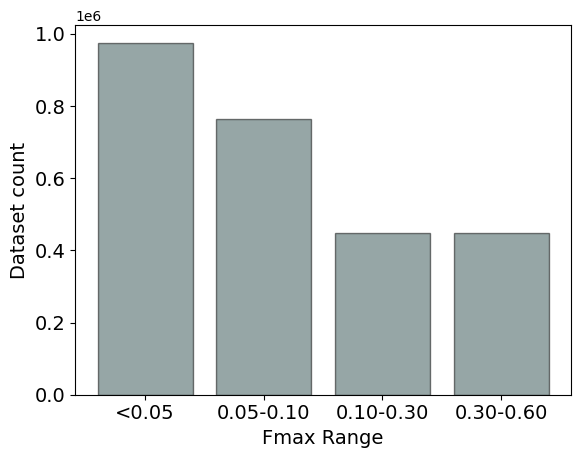

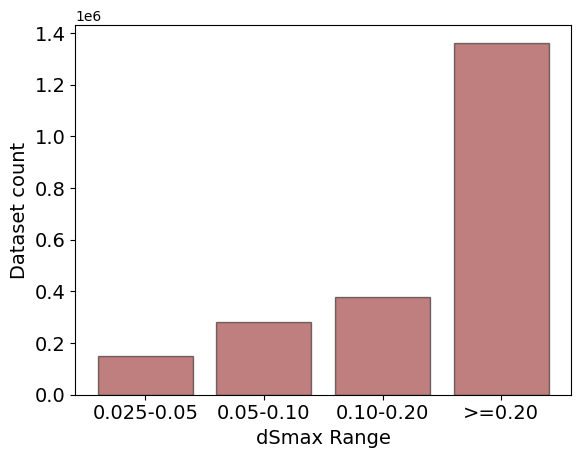

In [28]:
# Read the selected_frames.parquet file
df = pd.read_parquet('selected_frames.parquet')


# Collect dE, Fmax, dS values
dE_values = df['dE'].to_numpy()
Fmax_values = df['Fmax'].to_numpy()
dSmax_values = df['dSmax'].to_numpy()

dE = np.concatenate(dE_values)
Fmax = np.concatenate(Fmax_values)
dSmax = np.concatenate(dSmax_values)

total_count = len(dSmax)
# Get total count
print(f"Total dataset count: {total_count}")

relaxed_count = ((dSmax == 0)).sum()

bin1_count = ((Fmax < 0.05)).sum()
bin1_percent = bin1_count / total_count
bin2_count = ((Fmax >= 0.05) & (Fmax < 0.10)).sum()
bin2_percent = bin2_count / total_count
bin3_count = ((Fmax >= 0.10) & (Fmax < 0.30)).sum()
bin3_percent = bin3_count / total_count
bin4_count = ((Fmax >= 0.30) & (Fmax < 0.60)).sum()
bin4_percent = bin4_count / total_count
total = bin1_count + bin2_count + bin3_count + bin4_count
print(f"Relaxed: {relaxed_count} \nBin 1: {bin1_count} ({bin1_percent}) \nBin 2: {bin2_count} ({bin2_percent}) \nBin 3: {bin3_count} ({bin3_percent}) \nBin 4: {bin4_count} ({bin4_percent}) \nTotal: {total}")

# Bar chart of bin counts (Fmax)
bin_counts = [bin1_count, bin2_count, bin3_count, bin4_count]
bin_labels = ['<0.05', '0.05-0.10', '0.10-0.30', '0.30-0.60']
plt.figure()
plt.bar(bin_labels, bin_counts, color="darkslategray", alpha=0.5, edgecolor="black")
plt.xlabel('Fmax Range', fontsize=14)
plt.ylabel('Dataset count', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14);
plt.savefig('plots/is2s_bin_counts.pdf', dpi=300, bbox_inches='tight')

# Bar chart of dSmax ranges (excluding dSmax == 0)
dSmax_nonzero = dSmax[dSmax != 0]
dSmax_bin1 = ((dSmax_nonzero > 0) & (dSmax_nonzero < 0.025)).sum()
dSmax_bin2 = ((dSmax_nonzero >= 0.025) & (dSmax_nonzero < 0.05)).sum()
dSmax_bin3 = ((dSmax_nonzero >= 0.05) & (dSmax_nonzero < 0.10)).sum()
dSmax_bin4 = ((dSmax_nonzero >= 0.10) & (dSmax_nonzero < 0.20)).sum()
dSmax_bin5 = ((dSmax_nonzero >= 0.20)).sum()

dSmax_counts = [dSmax_bin2, dSmax_bin3, dSmax_bin4, dSmax_bin5]
dSmax_labels = ['0.025-0.05', '0.05-0.10', '0.10-0.20', '>=0.20']
plt.figure()
plt.bar(dSmax_labels, dSmax_counts, color="maroon", alpha=0.5, edgecolor="black")
plt.xlabel('dSmax Range', fontsize=14)
plt.ylabel('Dataset count', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14);
plt.savefig('plots/is2s_dSmax_range.pdf', dpi=300, bbox_inches='tight')

"""
plt.figure()
bin1_dist = dSmax[Fmax < 0.05]
bins = np.arange(0, 0.20, 0.01)
plt.hist(bin1_dist, bins=bins)
plt.xlabel('dSmax')
plt.ylabel('Count');

plt.figure()
bin2_dist = dSmax[(Fmax >= 0.05) & (Fmax < 0.10)]
bins = np.arange(0, 0.20, 0.01)
plt.hist(bin2_dist, bins=bins)
plt.xlabel('dSmax')
plt.ylabel('Count');

plt.figure()
bin3_dist = dSmax[(Fmax >= 0.10) & (Fmax < 0.60)]
bins = np.arange(0, 0.60, 0.01)
plt.hist(bin3_dist, bins=bins)
plt.xlabel('dSmax')
plt.ylabel('Count');

plt.figure()
bin3_dist = dSmax
bins = np.arange(0, 0.60, 0.01)
plt.hist(dSmax, bins=bins)
plt.xlabel('dSmax')
plt.ylabel('Count');
"""

In [5]:
# Collect dE, Fmax, dS values
dE_values = df['dE'].to_numpy()
Fmax_values = df['Fmax'].to_numpy()
dSmax_values = df['dSmax'].to_numpy()

count = 0 
count2 = 0
for idx in range(0, len(dSmax_values)):
    s = dSmax_values[idx]    
    diff = abs(s[:, None] - s[None, :])
    
    mask = ~np.eye(diff.shape[0], dtype=bool)
    
    hits = (diff < 0.025) & (diff != 0)
    hits = np.unique(hits)

    if hits.any():
        count += hits.sum()
        count2 += 1 if np.argmin(dSmax_values[idx]) != 0 else 0 
        
       
   
print(count, count2)

0 0
